# Sales forecasting for 7 countries (SARIMA)

**Question:** what will monthly revenue look like over the next 12 months in each market, without a manual Excel process?

**Pipeline**
1. Load 7 country sales files and join them with product, geography and manufacturer master data (pandas).
2. Aggregate to monthly revenue per country.
3. Test stationarity with the augmented Dickey-Fuller test.
4. Tune SARIMA hyperparameters per country (grid search, lowest AIC).
5. Backtest: train on 2011-2017, forecast 2018, measure accuracy against actual 2018 revenue.
6. Refit on all data and forecast the next 12 months, with charts in matplotlib.

In [1]:
import itertools, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")  # statsmodels convergence chatter during the grid search
DATA = Path("data")
IMG = Path("images"); IMG.mkdir(exist_ok=True)
COUNTRIES = ["Australia", "Canada", "Germany", "Japan", "Mexico", "Nigeria", "USA"]
millions = FuncFormatter(lambda x, pos: f"{x / 1e6:.1f}M" if abs(x) >= 1e6 else f"{x / 1e3:.0f}K")

## 1. Load and join the data

In [2]:
frames = []
for c in COUNTRIES:
    df = pd.read_csv(DATA / f"{c}.csv", usecols=["ProductID", "Date", "Zip", "Units", "Revenue", "Country"])
    df["Country"] = c
    frames.append(df)
sales = pd.concat(frames, ignore_index=True)
sales["Date"] = pd.to_datetime(sales["Date"], errors="coerce")
sales["Zip"] = sales["Zip"].astype(str)

geo = pd.read_excel(DATA / "MDM_GEO.xlsx")
product = pd.read_excel(DATA / "MDM_PRODUCT.xlsx")
manufacturer = pd.read_excel(DATA / "MDM_MANUFACTURER.xlsx")
geo["Zip"] = geo["Zip"].astype(str)
geo = geo.drop_duplicates(["Zip", "Country"])

rows_before = len(sales)
merged = (sales
          .merge(geo, on=["Zip", "Country"], how="left")
          .merge(product, on="ProductID", how="left")
          .merge(manufacturer, on="ManufacturerID", how="left"))
assert len(merged) == rows_before, "a join duplicated rows"

print(f"Sales rows: {rows_before:,}")
print(f"Date range: {merged['Date'].min():%Y-%m-%d} to {merged['Date'].max():%Y-%m-%d}")
print(f"Rows matched to a product: {merged['Product'].notna().mean():.1%}")
merged.groupby("Country")["Revenue"].sum().sort_values(ascending=False).map("{:,.0f}".format)

Sales rows: 7,235,490
Date range: 2011-01-04 to 2018-12-31


Rows matched to a product: 100.0%


Country
USA          1,697,110,400
Australia      761,681,611
Japan          227,982,218
Nigeria         85,003,218
Germany         69,249,072
Mexico          51,944,904
Canada          18,253,884
Name: Revenue, dtype: object

## 2. Monthly revenue per country

(96, 7) 2011-01-01 to 2018-12-01


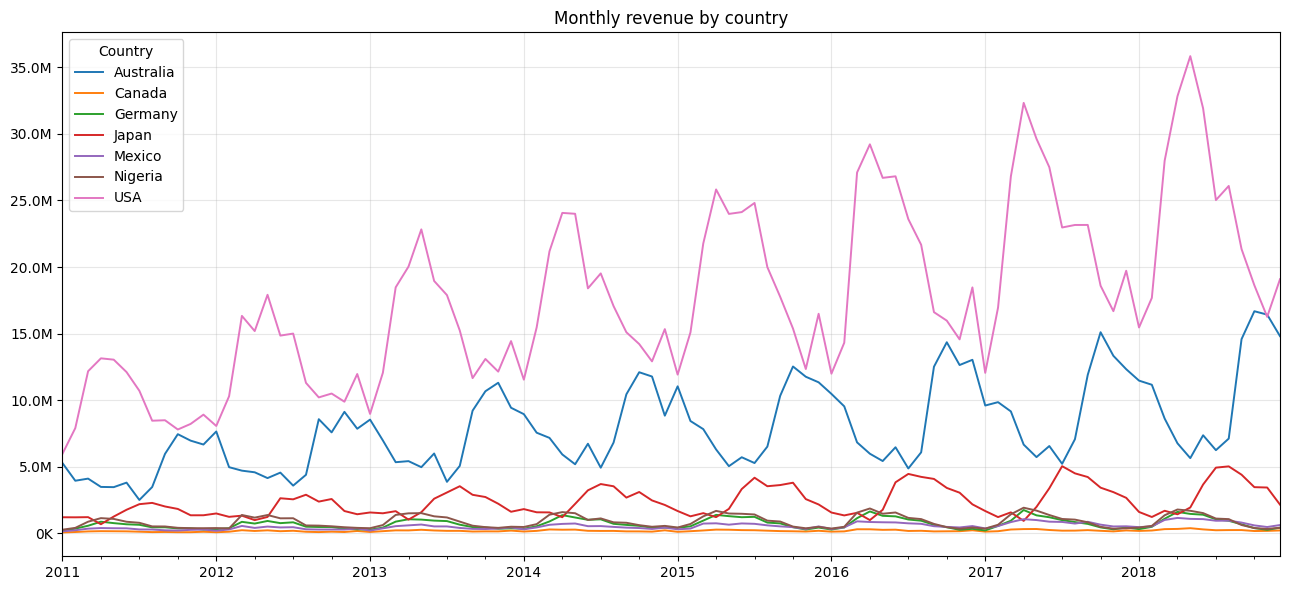

In [3]:
monthly = (merged.dropna(subset=["Date"])
           .groupby(["Country", pd.Grouper(key="Date", freq="MS")])["Revenue"].sum()
           .unstack("Country").asfreq("MS").ffill())
print(monthly.shape, monthly.index.min().date(), "to", monthly.index.max().date())

fig, ax = plt.subplots(figsize=(13, 6))
monthly.plot(ax=ax, linewidth=1.4)
ax.yaxis.set_major_formatter(millions)
ax.set_title("Monthly revenue by country"); ax.set_xlabel(""); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(IMG / "monthly_revenue.png", dpi=120); plt.show()

## 3. Stationarity: augmented Dickey-Fuller test

H0: the series has a unit root (not stationary). p < 0.05 rejects H0.
We test the raw series, after a first difference (d=1), and after a first plus seasonal difference (d=1, D=1, s=12).

In [4]:
def adf_p(series):
    return adfuller(series.dropna(), autolag="AIC")[1]

adf = pd.DataFrame({
    "raw": monthly.apply(adf_p),
    "d=1": monthly.diff().apply(adf_p),
    "d=1, D=1 (s=12)": monthly.diff().diff(12).apply(adf_p),
}).round(4)
adf["stationary after d=1, D=1"] = adf["d=1, D=1 (s=12)"] < 0.05
adf

,raw,d=1,"d=1, D=1 (s=12)","stationary after d=1, D=1"
Country,,,,
Australia,0.3857,0.0000,0.0727,False
Canada,0.5302,0.0000,0.2388,False
Germany,0.0985,0.0002,0.0000,True
Japan,0.0472,0.0000,0.0000,True
Mexico,0.9800,0.0000,0.0152,True
Nigeria,0.0016,0.0000,0.0008,True
USA,0.1397,0.0000,0.0000,True


## 4. Hyperparameter tuning (grid search on AIC)

Training data: 2011-2017. For every country we try p, q in {0, 1, 2} and P, Q in {0, 1},
and keep the order with the lowest AIC. d=1 because every series is stationary after one difference
(Dickey-Fuller p < 0.05 above); D=1 with a 12-month season to remove the yearly pattern.

In [5]:
train = monthly[monthly.index < "2018-01-01"]
test = monthly[(monthly.index >= "2018-01-01") & (monthly.index < "2019-01-01")]

grid = [((p, 1, q), (P, 1, Q, 12)) for p, q, P, Q in itertools.product(range(3), range(3), range(2), range(2))]

def tune(series):
    best = None
    for order, seasonal in grid:
        try:
            res = SARIMAX(series, order=order, seasonal_order=seasonal,
                          enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        except Exception:
            continue
        if best is None or res.aic < best[2]:
            best = (order, seasonal, res.aic)
    return best

t0 = time.time()
best = {c: tune(train[c]) for c in COUNTRIES}
print(f"{len(grid)} candidate models x {len(COUNTRIES)} countries in {time.time() - t0:.0f}s")
pd.DataFrame(best, index=["order (p,d,q)", "seasonal (P,D,Q,s)", "AIC"]).T

36 candidate models x 7 countries in 35s


,"order (p,d,q)","seasonal (P,D,Q,s)",AIC
Australia,"(0, 1, 2)","(0, 1, 1, 12)",1706.347625
Canada,"(2, 1, 2)","(1, 1, 1, 12)",1317.186691
Germany,"(0, 1, 2)","(1, 1, 1, 12)",1461.68519
Japan,"(0, 1, 2)","(0, 1, 1, 12)",1587.48188
Mexico,"(1, 1, 2)","(0, 1, 1, 12)",1422.833002
Nigeria,"(0, 1, 2)","(0, 1, 1, 12)",1495.956807
USA,"(0, 1, 2)","(0, 1, 1, 12)",1776.672357


## 5. Backtest: forecast 2018 and compare with actual revenue

Accuracy = 1 - MAPE (mean absolute percentage error over the 12 months of 2018).
The overall figure weights each country by its 2018 revenue (1 - WAPE).

In [6]:
rows, preds = [], {}
for c in COUNTRIES:
    order, seasonal, _ = best[c]
    res = SARIMAX(train[c], order=order, seasonal_order=seasonal,
                  enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    pred = res.get_forecast(steps=len(test)).predicted_mean
    pred.index = test.index
    preds[c] = pred
    ape = (test[c] - pred).abs() / test[c]
    rows.append({"Country": c, "MAPE %": ape.mean() * 100, "Accuracy %": (1 - ape.mean()) * 100,
                 "2018 actual": test[c].sum(), "2018 forecast": pred.sum()})

backtest = pd.DataFrame(rows).set_index("Country")
wape = sum((test[c] - preds[c]).abs().sum() for c in COUNTRIES) / test[COUNTRIES].to_numpy().sum()
print(f"Overall accuracy (1 - WAPE, revenue-weighted): {(1 - wape) * 100:.1f}%")
print(f"Average accuracy across the 7 countries:      {backtest['Accuracy %'].mean():.1f}%")
backtest.style.format({"MAPE %": "{:.1f}", "Accuracy %": "{:.1f}", "2018 actual": "{:,.0f}", "2018 forecast": "{:,.0f}"})

Overall accuracy (1 - WAPE, revenue-weighted): 91.5%
Average accuracy across the 7 countries:      89.8%


,MAPE %,Accuracy %,2018 actual,2018 forecast
Country,,,,
Australia,9.4,90.6,"126,869,817","117,164,554"
Canada,10.4,89.6,"3,012,098","2,845,854"
Germany,12.9,87.1,"10,111,269","9,964,229"
Japan,10.2,89.8,"34,990,478","35,789,892"
Mexico,10.9,89.1,"9,696,867","9,844,086"
Nigeria,9.6,90.4,"11,297,041","11,426,280"
USA,8.1,91.9,"288,128,713","291,738,055"


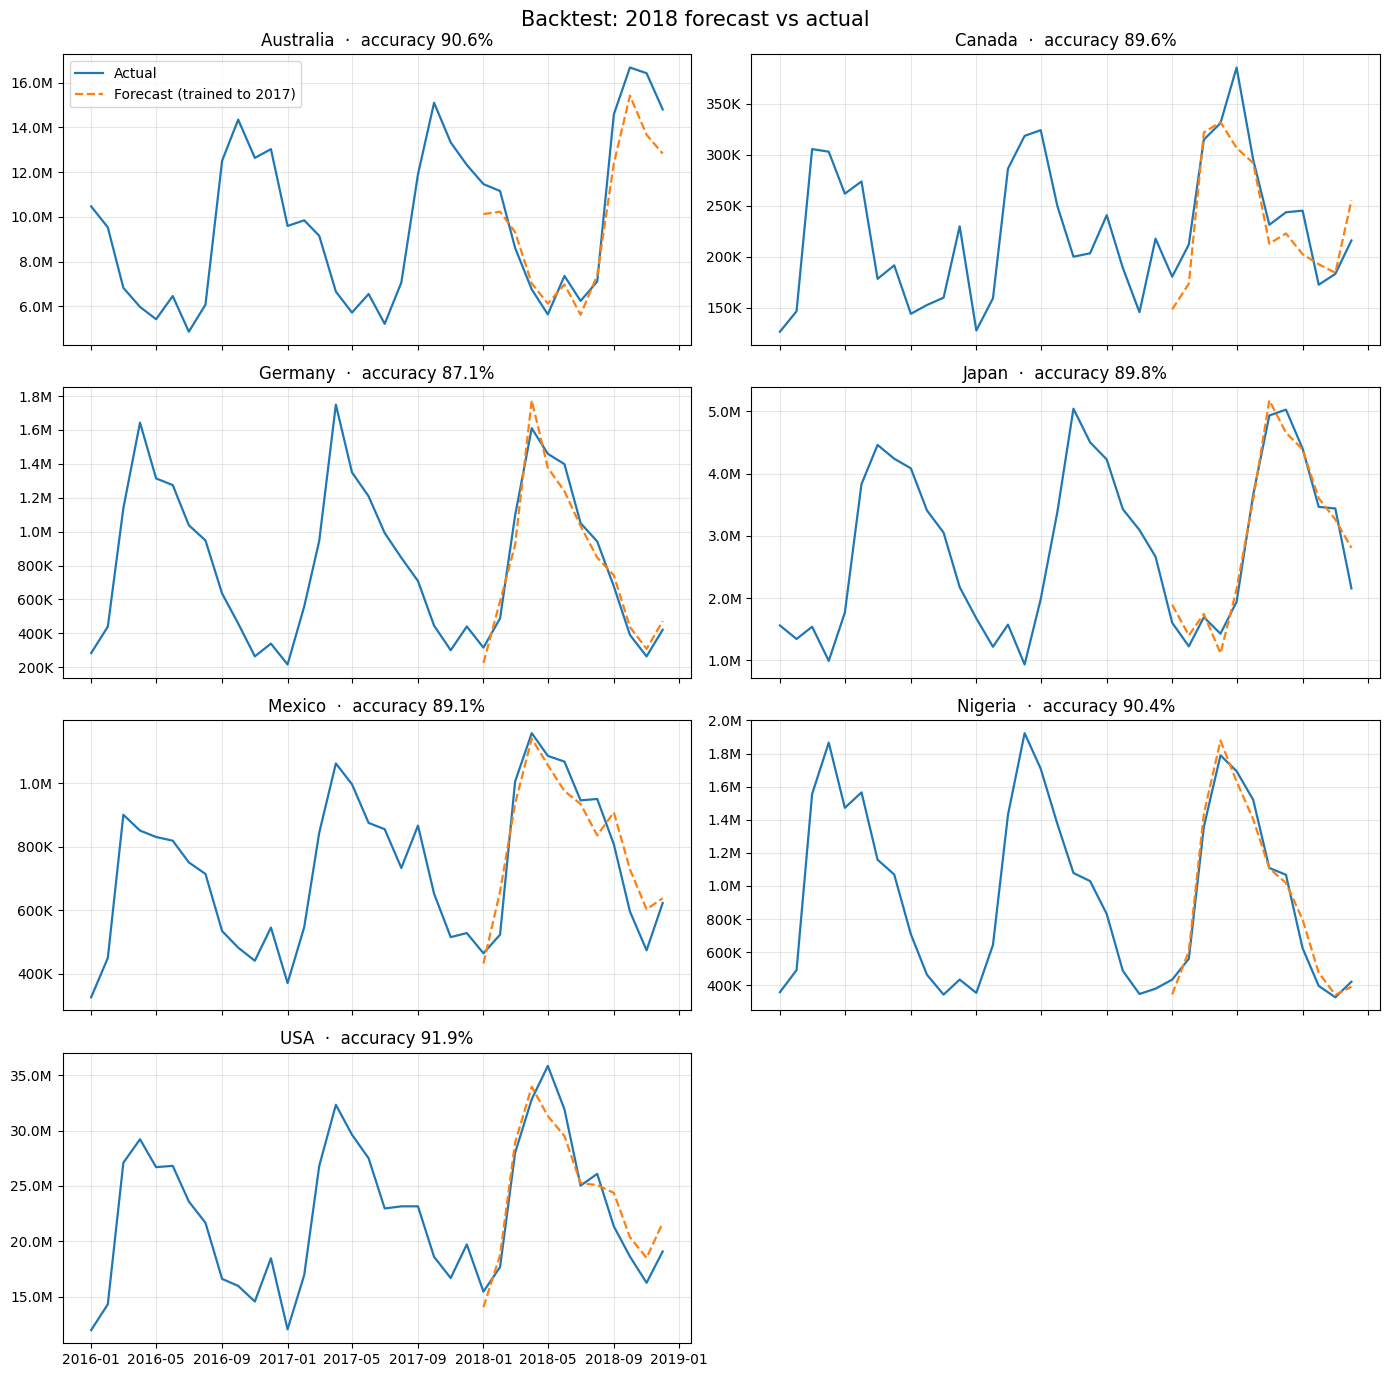

In [7]:
fig, axes = plt.subplots(4, 2, figsize=(14, 14), sharex=True)
for ax, c in zip(axes.flat, COUNTRIES):
    ax.plot(monthly.loc["2016":"2018", c], label="Actual", linewidth=1.6)
    ax.plot(preds[c], label="Forecast (trained to 2017)", linestyle="--", linewidth=1.6)
    ax.set_title(f"{c}  ·  accuracy {backtest.loc[c, 'Accuracy %']:.1f}%")
    ax.yaxis.set_major_formatter(millions); ax.grid(alpha=.3)
axes.flat[0].legend(); axes.flat[-1].axis("off")
fig.suptitle("Backtest: 2018 forecast vs actual", fontsize=15)
fig.tight_layout(); fig.savefig(IMG / "backtest_2018.png", dpi=120); plt.show()

## 6. Final 12-month forecast (2019), refit on all data

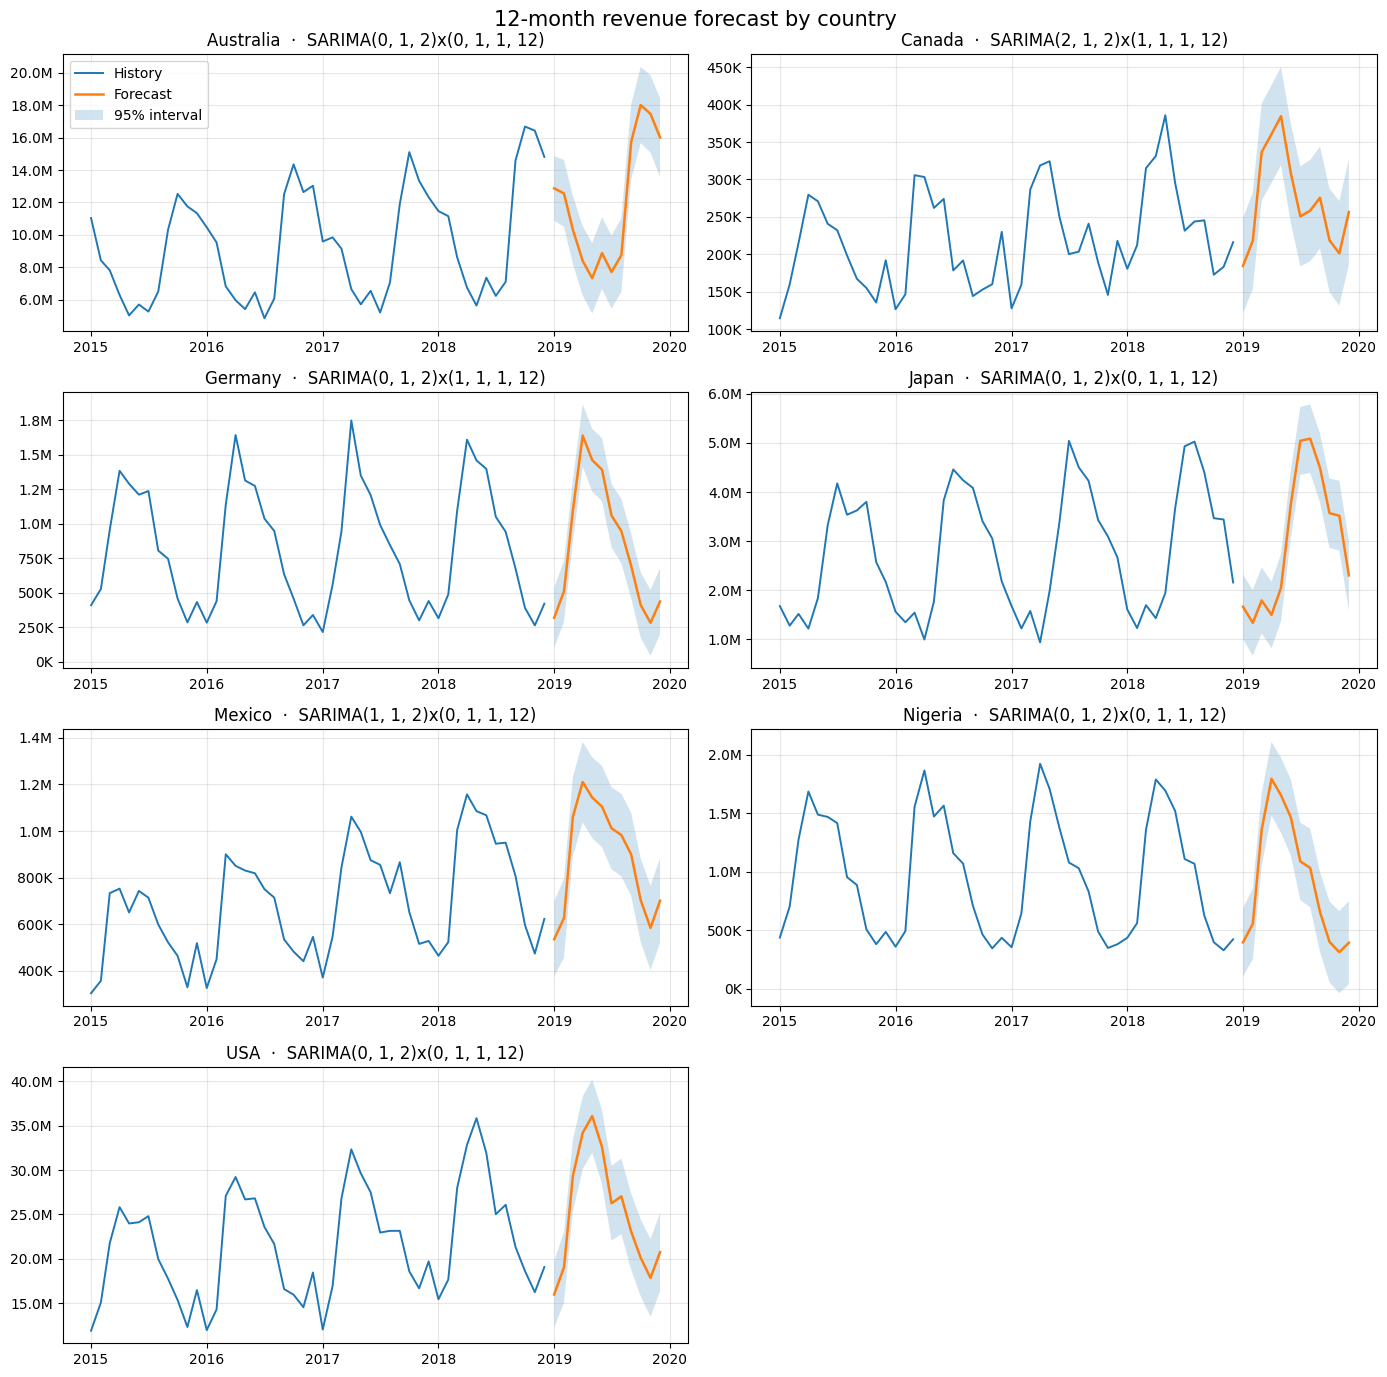

,Australia,Canada,Germany,Japan,Mexico,Nigeria,USA
2019-01,12.870000,0.180000,0.320000,1.660000,0.540000,0.390000,16.000000
2019-02,12.560000,0.220000,0.510000,1.330000,0.630000,0.550000,19.050000
2019-03,10.330000,0.340000,1.090000,1.790000,1.060000,1.360000,29.330000
2019-04,8.400000,0.360000,1.640000,1.500000,1.210000,1.790000,34.190000
2019-05,7.330000,0.380000,1.460000,2.050000,1.140000,1.650000,36.070000
2019-06,8.880000,0.310000,1.390000,3.750000,1.100000,1.460000,32.590000
2019-07,7.720000,0.250000,1.060000,5.040000,1.010000,1.090000,26.260000
2019-08,8.760000,0.260000,0.950000,5.090000,0.980000,1.030000,27.040000
2019-09,15.740000,0.280000,0.700000,4.490000,0.900000,0.650000,23.070000
2019-10,18.000000,0.220000,0.410000,3.570000,0.700000,0.400000,20.130000


In [8]:
forecast = {}
fig, axes = plt.subplots(4, 2, figsize=(14, 14))
for ax, c in zip(axes.flat, COUNTRIES):
    order, seasonal, _ = best[c]
    res = SARIMAX(monthly[c], order=order, seasonal_order=seasonal,
                  enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    fc = res.get_forecast(steps=12)
    mean, ci = fc.predicted_mean, fc.conf_int()
    forecast[c] = mean
    ax.plot(monthly[c]["2015":], label="History", linewidth=1.4)
    ax.plot(mean, label="Forecast", linewidth=1.8)
    ax.fill_between(mean.index, ci.iloc[:, 0], ci.iloc[:, 1], alpha=.2, label="95% interval")
    ax.set_title(f"{c}  ·  SARIMA{order}x{seasonal}")
    ax.yaxis.set_major_formatter(millions); ax.grid(alpha=.3)
axes.flat[0].legend(); axes.flat[-1].axis("off")
fig.suptitle("12-month revenue forecast by country", fontsize=15)
fig.tight_layout(); fig.savefig(IMG / "forecast_12m.png", dpi=120); plt.show()

forecast = pd.DataFrame(forecast)
forecast.index = forecast.index.strftime("%Y-%m")
forecast.to_csv("forecast_12m.csv")
(forecast / 1e6).round(2).style.set_caption("Forecast revenue, millions")

## Notes

- Raw data is not included in this repository (course case-study data, and the USA file is larger than GitHub's limit).
  Put the 7 country CSVs and the 3 MDM workbooks in `data/` to rerun the notebook.
- SARIMA is fitted with statsmodels' `SARIMAX` class without exogenous variables.